C:\Users\Trang\AppData\Local\Temp\ipykernel_37372\3168032773.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


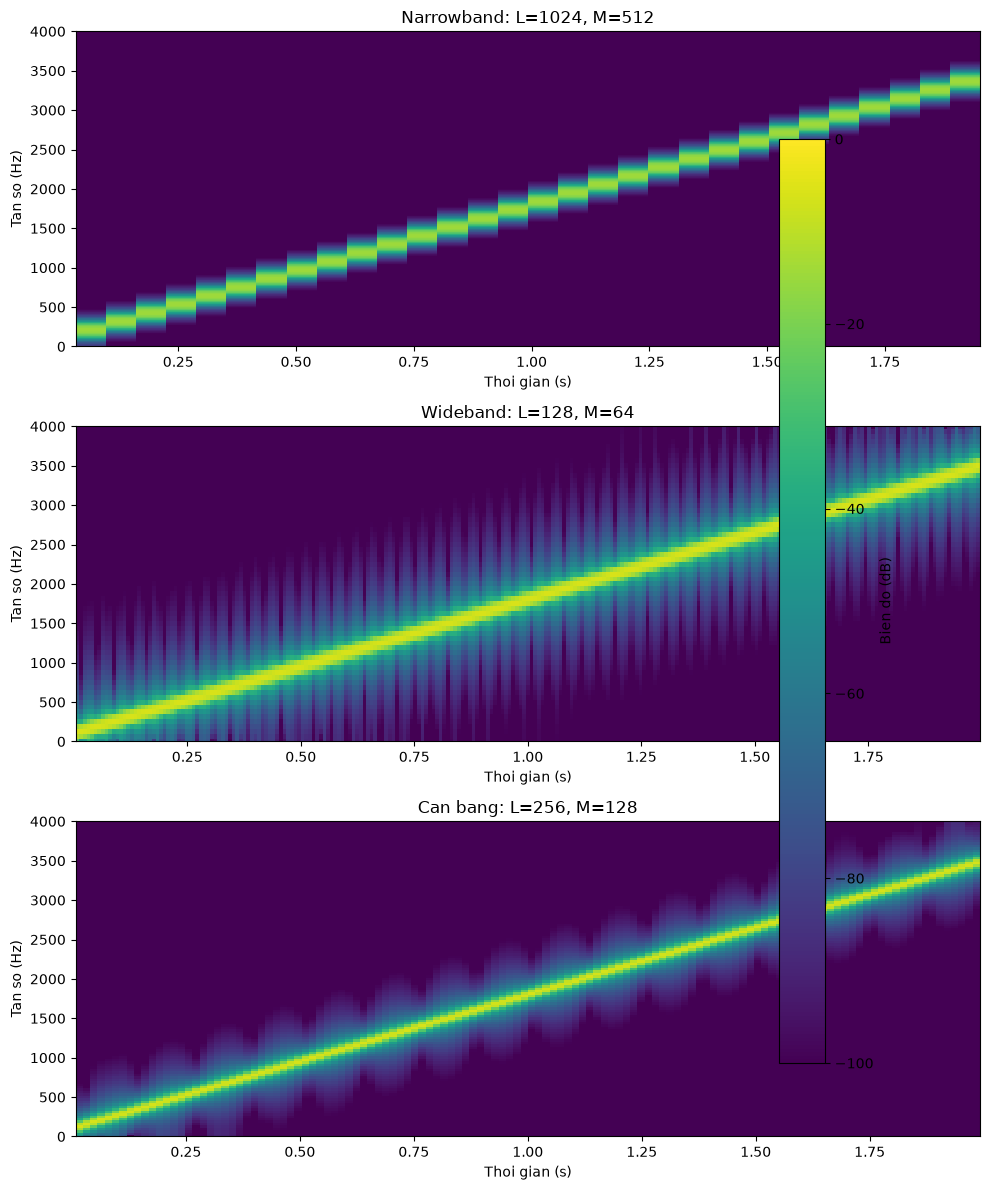

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft

# 1. Tao tin hieu Linear Chirp
fs = 8000
T = 2
f0 = 100
f1 = 3500

t = np.arange(0, T, 1/fs)
x = np.sin(2 * np.pi * (f0*t + (f1-f0)*t**2/(2*T)))

# 2. Cau hinh cac truong hop
cases = [
    ("Narrowband: L=1024, M=512", 1024, 512),
    ("Wideband: L=128, M=64", 128, 64),
    ("Can bang: L=256, M=128", 256, 128)
]

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for ax, (title, L, M) in zip(axes, cases):
    # Tinh STFT
    f, tt, X = stft(
        x,
        fs=fs,
        window="hann",
        nperseg=L,
        noverlap=M,
        nfft=L,
        boundary=None,
        padded=False
    )

    # Chuyen bien do sang thang dB
    SdB = 20 * np.log10(np.abs(X) + 1e-8)

    # Ve Spectrogram
    mesh = ax.pcolormesh(
        tt, f, SdB,
        shading="auto",
        vmin=-100,
        vmax=0,
        cmap="viridis"
    )

    ax.set_title(title)
    ax.set_xlabel("Thoi gian (s)")
    ax.set_ylabel("Tan so (Hz)")
    ax.set_ylim(0, 4000)

fig.colorbar(mesh, ax=axes, label="Bien do (dB)")
plt.tight_layout()
plt.show()
